## Ejercicio 4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

### Inciso a)

Para una matriz con 64 columnas, el teorema de rango y nulidad establece que

$$\operatorname{rango}(A)+\dim(\operatorname{Nul}(A))=64.$$

Una imagen se determina de manera única a partir de mediciones compatibles si
$\operatorname{rango}(A)=64$. En ese caso el espacio nulo contiene solamente al vector cero.
Si existe $v\ne0$ tal que $Av=0$, entonces

$$A(x+\gamma v)=Ax+\gamma Av=Ax.$$

Por lo tanto, todas esas imágenes producen las mismas mediciones. Tener al menos 64 filas
es necesario para alcanzar rango 64, pero no alcanza si hay filas dependientes.

### Inciso b)

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

In [5]:
matrices = {"A2": A2, "A4": A4, "A7": A7}
print(f"{'Matriz':<8} {'Dimensiones':<15} {'Rango':>7} {'Nulidad':>9} {'Filas-rango':>13} {'Única':>8}")
for nombre, A in matrices.items():
    rango = np.linalg.matrix_rank(A)
    nulidad = A.shape[1] - rango
    redundancia = A.shape[0] - rango
    print(f"{nombre:<8} {str(A.shape):<15} {rango:7d} {nulidad:9d} {redundancia:13d} {str(nulidad == 0):>8}")

assert [np.linalg.matrix_rank(A) for A in matrices.values()] == [15, 39, 64]

Matriz   Dimensiones       Rango   Nulidad   Filas-rango    Única
A2       (16, 64)             15        49             1    False
A4       (46, 64)             39        25             7    False
A7       (119, 64)            64         0            55     True


`A2` tiene 16 filas y rango 15; `A4` tiene 46 filas y rango 39; `A7` tiene 119 filas y rango 64.
Las nulidades son 49, 25 y 0, respectivamente. Solamente `A7` permite recuperar una imagen
de manera única en el modelo sin ruido.

En los tres casos hay mediciones redundantes: la cantidad de filas supera al rango.
Por ejemplo, con `A2` la suma de todas las mediciones por filas coincide con la suma de
todas las mediciones por columnas, porque ambas suman toda la imagen.

### Inciso c)

Norma de v: 1.0000000000000002
Norma de A4 @ v: 3.212254547260621e-15
Diferencia entre las imágenes: 1.0000000000000002
Diferencia entre las mediciones: 3.289815197292142e-15


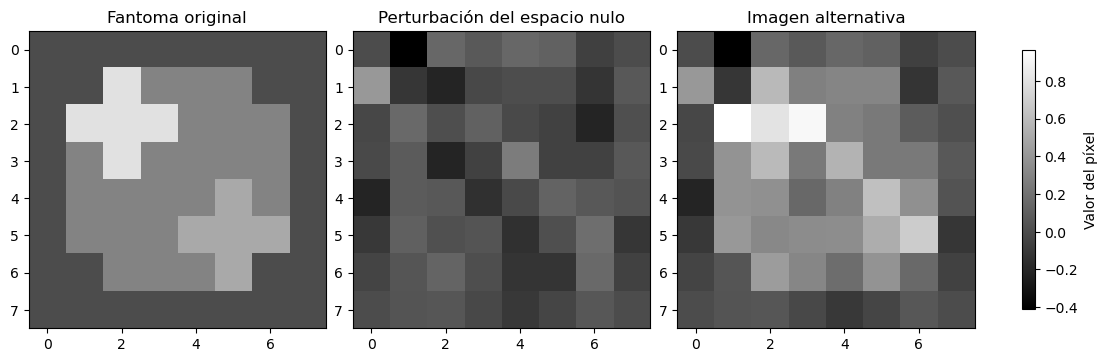

In [6]:
U, valores_singulares, Vt = np.linalg.svd(A4, full_matrices=True)
rango4 = np.linalg.matrix_rank(A4)
v = Vt[rango4].copy()

gamma = 1.0
b4 = A4 @ x_fantoma
x_alt = x_fantoma + gamma * v
b_alt = A4 @ x_alt

print("Norma de v:", np.linalg.norm(v))
print("Norma de A4 @ v:", np.linalg.norm(A4 @ v))
print("Diferencia entre las imágenes:", np.linalg.norm(x_alt - x_fantoma))
print("Diferencia entre las mediciones:", np.linalg.norm(b_alt - b4))
assert np.linalg.norm(v) > 0.9
assert np.allclose(A4 @ v, 0, atol=1e-12)
assert np.allclose(b_alt, b4)

imagenes = [X_fantoma, v.reshape(n, n), x_alt.reshape(n, n)]
titulos = ["Fantoma original", "Perturbación del espacio nulo", "Imagen alternativa"]
vmin = min(imagen.min() for imagen in imagenes)
vmax = max(imagen.max() for imagen in imagenes)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, imagen, titulo in zip(axs, imagenes, titulos):
    im = ax.imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(titulo)
fig.colorbar(axs[0].images[0], ax=axs, label="Valor del píxel", shrink=0.8)
plt.show()

Las imágenes son diferentes, pero sus mediciones coinciden salvo errores de redondeo.
La perturbación $v$ redistribuye atenuaciones de modo que sus aportes se cancelan en todos
los rayos de `A4`. Esa parte de la imagen resulta invisible para esta adquisición.

La SVD devuelve vectores ortonormales en las filas de `Vt`. Al usar `full_matrices=True`
obtenemos las 64 direcciones, incluidas las del espacio nulo. Elegimos una que está después
de las direcciones correspondientes al rango. La imagen alternativa puede tener valores
negativos: sirve para mostrar la falta de unicidad del sistema lineal sin restricciones
adicionales, no para imponer un modelo físico de atenuaciones no negativas.